In [ ]:
# Cell 1 — Install dependencies
!pip install transformers datasets accelerate scikit-learn seaborn matplotlib pandas torch --quiet
!pip install evaluate --quiet  # HuggingFace evaluation library

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.2 MB/s eta 0:00:00


In [ ]:
# Cell 2 — Mount Google Drive (to save model and dataset)
from google.colab import drive
drive.mount('/content/drive')

# Create a project directory
import os
os.makedirs('/content/drive/MyDrive/SALITAyo_NLI', exist_ok=True)
PROJECT_DIR = '/content/drive/MyDrive/SALITAyo_NLI'

Mounted at /content/drive


In [ ]:
# Cell 3 — Check GPU
import torch
print("GPU available:", torch.cuda.is_available())
print("GPU name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")
print("CUDA version:", torch.version.cuda)

GPU available: True
GPU name: Tesla T4
CUDA version: 12.8


In [ ]:
from google.colab import files
uploaded = files.upload()  # Opens file picker — upload your CSV

Saving salitayo_custom.csv to salitayo_custom.csv


In [ ]:
# ============================================================
# SALITAyo NLI — Part 2: Dataset Download & Split
# Paste this entire file into a Google Colab cell.
# Prerequisite: upload salitayo_custom.csv to /content/ first.
# ============================================================

# ── 1. Install dependencies ──────────────────────────────────
!pip install -q datasets pandas scikit-learn

# ── 2. Imports ───────────────────────────────────────────────
import pandas as pd
from datasets import load_dataset
from sklearn.model_selection import GroupShuffleSplit
from google.colab import drive
import os

# ── 3. Mount Google Drive ────────────────────────────────────
drive.mount("/content/drive")
OUTPUT_DIR = "/content/drive/MyDrive/SALITAyo_NLI"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ── 4. Label maps ─────────────────────────────────────────────
# MultiNLI and SNLI both use the same numeric mapping
NLI_LABEL_MAP = {0: "entailment", 1: "neutral", 2: "contradiction"}

# ── 5. Load MultiNLI (train split only; validation_matched for diversity) ──
print("Loading MultiNLI …")
mnli_raw = load_dataset("multi_nli", split="train")

mnli_df = pd.DataFrame({
    "premise":    mnli_raw["premise"],
    "hypothesis": mnli_raw["hypothesis"],
    "label":      mnli_raw["label"],
})

# Drop unlabeled rows (label == -1)
mnli_df = mnli_df[mnli_df["label"] != -1].copy()

# Remap numeric → string labels
mnli_df["label"] = mnli_df["label"].map(NLI_LABEL_MAP)

# Sample 666 per class
MNLI_PER_CLASS = 666
mnli_sampled = (
    mnli_df
    .groupby("label", group_keys=False)
    .apply(lambda g: g.sample(n=MNLI_PER_CLASS, random_state=42))
    .reset_index(drop=True)
)
print(f"MultiNLI sampled: {len(mnli_sampled)} rows | {mnli_sampled['label'].value_counts().to_dict()}")

# ── 6. Load SNLI ─────────────────────────────────────────────
print("Loading SNLI …")
snli_raw = load_dataset("snli", split="train")

snli_df = pd.DataFrame({
    "premise":    snli_raw["premise"],
    "hypothesis": snli_raw["hypothesis"],
    "label":      snli_raw["label"],
})

# Drop unlabeled rows (label == -1) — SNLI contains some
snli_df = snli_df[snli_df["label"] != -1].copy()

# Remap numeric → string labels
snli_df["label"] = snli_df["label"].map(NLI_LABEL_MAP)

# Sample 334 per class
SNLI_PER_CLASS = 334
snli_sampled = (
    snli_df
    .groupby("label", group_keys=False)
    .apply(lambda g: g.sample(n=SNLI_PER_CLASS, random_state=42))
    .reset_index(drop=True)
)
print(f"SNLI sampled:    {len(snli_sampled)} rows | {snli_sampled['label'].value_counts().to_dict()}")

# ── 7. Load custom SALITAyo dataset ──────────────────────────
print("Loading custom SALITAyo dataset …")
custom_df = pd.read_csv("/content/salitayo_custom.csv")
print(f"Custom rows:     {len(custom_df)} rows | {custom_df['label'].value_counts().to_dict()}")

# ── 8. Combine all sources ───────────────────────────────────
combined_df = pd.concat(
    [mnli_sampled, snli_sampled, custom_df],
    ignore_index=True
)[["premise", "hypothesis", "label"]]

print(f"\nCombined total:  {len(combined_df)} rows")
print("Class distribution:\n", combined_df["label"].value_counts())

# ── 9. Group-aware train / val / test split (70 / 15 / 15) ──
# Split by unique premise so the same premise never spans train and test.
#
# Strategy:
#   Pass 1 — GroupShuffleSplit pulls out 15 % of premise-groups → test
#   Pass 2 — GroupShuffleSplit on the remainder pulls out ~17.6 % → val
#             (15 % of total ÷ 85 % remaining ≈ 17.6 %)

premises = combined_df["premise"].values

gss_test = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
trainval_idx, test_idx = next(gss_test.split(combined_df, groups=premises))

trainval_df = combined_df.iloc[trainval_idx].reset_index(drop=True)
test_df     = combined_df.iloc[test_idx].reset_index(drop=True)

gss_val = GroupShuffleSplit(n_splits=1, test_size=0.176, random_state=42)
trainval_premises = trainval_df["premise"].values
train_idx, val_idx = next(gss_val.split(trainval_df, groups=trainval_premises))

train_df = trainval_df.iloc[train_idx].reset_index(drop=True)
val_df   = trainval_df.iloc[val_idx].reset_index(drop=True)

# ── 10. Save splits to Google Drive ──────────────────────────
train_path = os.path.join(OUTPUT_DIR, "train.csv")
val_path   = os.path.join(OUTPUT_DIR, "val.csv")
test_path  = os.path.join(OUTPUT_DIR, "test.csv")

train_df.to_csv(train_path, index=False)
val_df.to_csv(val_path,   index=False)
test_df.to_csv(test_path,  index=False)

print(f"\nFiles saved to {OUTPUT_DIR}")

# ── 11. Summary report ───────────────────────────────────────
print("\n" + "=" * 55)
print("SPLIT SUMMARY")
print("=" * 55)
print(f"Total rows  : {len(combined_df):>6}")
print(f"Train rows  : {len(train_df):>6}  ({len(train_df)/len(combined_df)*100:.1f} %)")
print(f"Val rows    : {len(val_df):>6}  ({len(val_df)/len(combined_df)*100:.1f} %)")
print(f"Test rows   : {len(test_df):>6}  ({len(test_df)/len(combined_df)*100:.1f} %)")

for split_name, split_data in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    print(f"\n{split_name} class distribution:")
    print(split_data["label"].value_counts().to_string())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loading MultiNLI …


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/214M [00:00<?, ?B/s]

data/validation_matched-00000-of-00001.p(…):   0%|          | 0.00/4.94M [00:00<?, ?B/s]

...

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/550152 [00:00<?, ? examples/s]

SNLI sampled:    1002 rows | {'contradiction': 334, 'entailment': 334, 'neutral': 334}
Loading custom SALITAyo dataset …
Custom rows:     232 rows | {'entailment': 58, 'contradiction': 58, 'neutral': 58, 'off_topic': 58}

Combined total:  3232 rows
Class distribution:
 label
contradiction    1058
entailment       1058
neutral          1058
off_topic          58
Name: count, dtype: int64

Files saved to /content/drive/MyDrive/SALITAyo_NLI

SPLIT SUMMARY
Total rows  :   3232
Train rows  :   2263  (70.0 %)
Val rows    :    485  (15.0 %)
Test rows   :    484  (15.0 %)

Train class distribution:
label
neutral          762
entailment       732
contradiction    729
off_topic         40

Val class distribution:
label
contradiction    171
entailment       162
neutral          143
off_topic          9

Test class distribution:
label
entailment       164
contradiction    158
neutral          153
off_topic          9


/tmp/ipykernel_16931/1770719415.py:73: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(n=SNLI_PER_CLASS, random_state=42))


In [ ]:
import pandas as pd

train_df = pd.read_csv('/content/drive/MyDrive/SALITAyo_NLI/train.csv')
val_df   = pd.read_csv('/content/drive/MyDrive/SALITAyo_NLI/val.csv')
test_df  = pd.read_csv('/content/drive/MyDrive/SALITAyo_NLI/test.csv')

# Quick sanity check
for name, df in [('train', train_df), ('val', val_df), ('test', test_df)]:
    print(f"\n{name}: {len(df)} rows")
    print(df['label'].value_counts())


train: 2263 rows
label
neutral          762
entailment       732
contradiction    729
off_topic         40
Name: count, dtype: int64

val: 485 rows
label
contradiction    171
entailment       162
neutral          143
off_topic          9
Name: count, dtype: int64

test: 484 rows
label
entailment       164
contradiction    158
neutral          153
off_topic          9
Name: count, dtype: int64


In [ ]:
# Cell 4 — All imports
import pandas as pd
import numpy as np
import torch
import os
import json
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, f1_score
)
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback
)
from datasets import Dataset, DatasetDict
import evaluate

print("All imports successful.")
print("PyTorch version:", torch.__version__)

All imports successful.
PyTorch version: 2.10.0+cu128


In [ ]:
# Load the pre-split files from Part 2
train_df = pd.read_csv('/content/drive/MyDrive/SALITAyo_NLI/train.csv')
val_df   = pd.read_csv('/content/drive/MyDrive/SALITAyo_NLI/val.csv')
test_df  = pd.read_csv('/content/drive/MyDrive/SALITAyo_NLI/test.csv')

# Define label mapping
LABEL2ID = {
    "entailment": 0,
    "contradiction": 1,
    "neutral": 2,
    "off_topic": 3
}
ID2LABEL = {v: k for k, v in LABEL2ID.items()}

# Apply label mapping to all splits
for df in [train_df, val_df, test_df]:
    df['label_id'] = df['label'].map(LABEL2ID)
    assert df['label_id'].isnull().sum() == 0, "Some labels failed to map!"

# Verify
for name, df in [('train', train_df), ('val', val_df), ('test', test_df)]:
    print(f"\n{name}: {len(df)} rows")
    print(df['label'].value_counts())

print("\nLabel mapping verified.")


train: 2263 rows
label
neutral          762
entailment       732
contradiction    729
off_topic         40
Name: count, dtype: int64

val: 485 rows
label
contradiction    171
entailment       162
neutral          143
off_topic          9
Name: count, dtype: int64

test: 484 rows
label
entailment       164
contradiction    158
neutral          153
off_topic          9
Name: count, dtype: int64

Label mapping verified.


In [ ]:
# Splits already created by Part 2 script — just verify
for name, df in [('train', train_df), ('val', val_df), ('test', test_df)]:
    print(f"{name}: {len(df)} rows | {df['label'].value_counts().to_dict()}")

# Save test set to Drive (mirrors what the guide does)
test_df.to_csv(f'{PROJECT_DIR}/test_set.csv', index=False)
print("Test set saved.")

train: 2263 rows | {'neutral': 762, 'entailment': 732, 'contradiction': 729, 'off_topic': 40}
val: 485 rows | {'contradiction': 171, 'entailment': 162, 'neutral': 143, 'off_topic': 9}
test: 484 rows | {'entailment': 164, 'contradiction': 158, 'neutral': 153, 'off_topic': 9}
Test set saved.


In [ ]:
MODEL_NAME = "cross-encoder/nli-deberta-v3-small"
NUM_LABELS = 4

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Load model — we override the classification head for 4 classes
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_LABELS,
    id2label=ID2LABEL,
    label2id=LABEL2ID,
    ignore_mismatched_sizes=True  # Required because we change from 3 to 4 classes
)

print(f"Model loaded: {MODEL_NAME}")
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

spm.model:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

added_tokens.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/301 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/568M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

DebertaV2ForSequenceClassification LOAD REPORT from: cross-encoder/nli-deberta-v3-small
Key                             | Status     |                                                                                     
--------------------------------+------------+-------------------------------------------------------------------------------------
deberta.embeddings.position_ids | UNEXPECTED |                                                                                     
classifier.bias                 | MISMATCH   | Reinit due to size mismatch ckpt: torch.Size([3]) vs model:torch.Size([4])          
classifier.weight               | MISMATCH   | Reinit due to size mismatch ckpt: torch.Size([3, 768]) vs model:torch.Size([4, 768])

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISMATCH	:ckpt weights were loaded, but they did not match the original empty weight shapes.


Model loaded: cross-encoder/nli-deberta-v3-small
Parameters: 141,897,988


In [ ]:
MAX_LENGTH = 256  # Suitable for sentence pairs; DeBERTa handles up to 512

def tokenize_function(examples):
    return tokenizer(
        examples['premise'],
        examples['hypothesis'],
        max_length=MAX_LENGTH,
        truncation=True,
        padding='max_length'
    )

# Convert to HuggingFace Dataset objects
def df_to_dataset(df):
    return Dataset.from_dict({
        'premise': df['premise'].tolist(),
        'hypothesis': df['hypothesis'].tolist(),
        'labels': df['label_id'].tolist()  # HuggingFace Trainer expects 'labels'
    })

train_dataset = df_to_dataset(train_df)
val_dataset = df_to_dataset(val_df)
test_dataset = df_to_dataset(test_df)

# Tokenize all splits
train_tokenized = train_dataset.map(tokenize_function, batched=True)
val_tokenized = val_dataset.map(tokenize_function, batched=True)
test_tokenized = test_dataset.map(tokenize_function, batched=True)

# Set format for PyTorch
train_tokenized.set_format('torch', columns=['input_ids', 'attention_mask', 'labels'])
val_tokenized.set_format('torch', columns=['input_ids', 'attention_mask', 'labels'])
test_tokenized.set_format('torch', columns=['input_ids', 'attention_mask', 'labels'])

print("Tokenization complete.")
print("Sample input_ids shape:", train_tokenized[0]['input_ids'].shape)

Map:   0%|          | 0/2263 [00:00<?, ? examples/s]

Map:   0%|          | 0/485 [00:00<?, ? examples/s]

Map:   0%|          | 0/484 [00:00<?, ? examples/s]

Tokenization complete.
Sample input_ids shape: torch.Size([256])


In [ ]:
accuracy_metric = evaluate.load("accuracy")
f1_metric = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    acc = accuracy_metric.compute(predictions=predictions, references=labels)
    f1 = f1_metric.compute(
        predictions=predictions,
        references=labels,
        average='weighted'  # Weighted accounts for class imbalance
    )

    return {
        "accuracy": acc["accuracy"],
        "f1_weighted": f1["f1"]
    }

In [ ]:
# Safety — redefine if not already in scope
PROJECT_DIR = '/content/drive/MyDrive/SALITAyo_NLI'

BATCH_SIZE = 16       # Works on T4 GPU with deberta-v3-small
NUM_EPOCHS = 5        # Use early stopping to prevent overfitting
LEARNING_RATE = 2e-5  # Standard for fine-tuning transformers
WARMUP_RATIO = 0.1    # 10% of steps for warmup

OUTPUT_DIR = f'{PROJECT_DIR}/model_output'

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,

    # Training config
    num_train_epochs=NUM_EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    learning_rate=LEARNING_RATE,
    warmup_ratio=WARMUP_RATIO,
    weight_decay=0.01,             # L2 regularization — prevents overfitting

    # Evaluation strategy
    eval_strategy="epoch",         # Evaluate after every epoch
    save_strategy="epoch",         # Save checkpoint after every epoch
    load_best_model_at_end=True,   # Load the best checkpoint at the end
    metric_for_best_model="f1_weighted",
    greater_is_better=True,

    # Logging
    logging_dir=f'{OUTPUT_DIR}/logs',
    logging_steps=50,
    report_to="none",              # Disable wandb/tensorboard (optional)

    # Reproducibility
    seed=42,

    # Performance
    fp16=True,                     # Mixed precision — speeds up T4 training
)

print("Training arguments configured.")

warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.
`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


Training arguments configured.


In [ ]:
# Early stopping: stop if val metric doesn't improve for 2 epochs
early_stopping = EarlyStoppingCallback(early_stopping_patience=2)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=val_tokenized,
    compute_metrics=compute_metrics,
    callbacks=[early_stopping]
)

print("Starting training...")
train_result = trainer.train()

print("\n--- Training Complete ---")
print("Training loss:", train_result.training_loss)
print("Training metrics:", train_result.metrics)

Starting training...


Epoch,Training Loss,Validation Loss,Accuracy,F1 Weighted
1,0.356384,0.170215,0.942268,0.939449
2,0.132412,0.155306,0.954639,0.954680
3,0.070701,0.177211,0.956701,0.956659
4,0.014379,0.204606,0.952577,0.952632
5,0.015561,0.205223,0.948454,0.948604


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['deberta.embeddings.LayerNorm.weight', 'deberta.embeddings.LayerNorm.bias', 'deberta.encoder.layer.0.attention.output.LayerNorm.weight', 'deberta.encoder.layer.0.attention.output.LayerNorm.bias', 'deberta.encoder.layer.0.output.LayerNorm.weight', 'deberta.encoder.layer.0.output.LayerNorm.bias', 'deberta.encoder.layer.1.attention.output.LayerNorm.weight', 'deberta.encoder.layer.1.attention.output.LayerNorm.bias', 'deberta.encoder.layer.1.output.LayerNorm.weight', 'deberta.encoder.layer.1.output.LayerNorm.bias', 'deberta.encoder.layer.2.attention.output.LayerNorm.weight', 'deberta.encoder.layer.2.attention.output.LayerNorm.bias', 'deberta.encoder.layer.2.output.LayerNorm.weight', 'deberta.encoder.layer.2.output.LayerNorm.bias', 'deberta.encoder.layer.3.attention.output.LayerNorm.weight', 'deberta.encoder.layer.3.attention.output.LayerNorm.bias', 'deberta.encoder.layer.3.output.LayerNorm.weight', 'deberta.encoder.layer.3.output.Laye


--- Training Complete ---
Training loss: 0.17107939121483917
Training metrics: {'train_runtime': 248.2068, 'train_samples_per_second': 45.587, 'train_steps_per_second': 2.861, 'total_flos': 749487733524480.0, 'train_loss': 0.17107939121483917, 'epoch': 5.0}


In [ ]:
FINAL_MODEL_DIR = f'{PROJECT_DIR}/final_model'

# Save model weights and config
trainer.save_model(FINAL_MODEL_DIR)

# Save tokenizer alongside the model
tokenizer.save_pretrained(FINAL_MODEL_DIR)

# Save label mapping
label_config = {
    "label2id": LABEL2ID,
    "id2label": ID2LABEL
}
with open(f'{FINAL_MODEL_DIR}/label_config.json', 'w') as f:
    json.dump(label_config, f, indent=2)

print(f"Model saved to: {FINAL_MODEL_DIR}")
print("Files saved:")
for f in os.listdir(FINAL_MODEL_DIR):
    print(" -", f)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to: /content/drive/MyDrive/SALITAyo_NLI/final_model
Files saved:
 - config.json
 - model.safetensors
 - training_args.bin
 - tokenizer_config.json
 - tokenizer.json
 - label_config.json


# **MODEL EVALUATION**

In [ ]:
# Evaluate on the held-out test set
print("Evaluating on test set...")
test_results = trainer.evaluate(test_tokenized)
print("Test results:", test_results)

Evaluating on test set...


Test results: {'eval_loss': 0.17202366888523102, 'eval_accuracy': 0.9628099173553719, 'eval_f1_weighted': 0.9627010426719103, 'eval_runtime': 2.3712, 'eval_samples_per_second': 204.117, 'eval_steps_per_second': 13.074, 'epoch': 5.0}


In [ ]:
# Get predictions
predictions_output = trainer.predict(test_tokenized)
y_pred = np.argmax(predictions_output.predictions, axis=-1)
y_true = test_df['label_id'].values

# Classification report
label_names = [ID2LABEL[i] for i in range(NUM_LABELS)]
report = classification_report(y_true, y_pred, target_names=label_names, digits=4)
print("=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)
print(report)

# Save report
with open(f'{PROJECT_DIR}/classification_report.txt', 'w') as f:
    f.write(report)

CLASSIFICATION REPORT
               precision    recall  f1-score   support

   entailment     0.9357    0.9756    0.9552       164
contradiction     0.9937    0.9937    0.9937       158
      neutral     0.9592    0.9216    0.9400       153
    off_topic     1.0000    0.8889    0.9412         9

     accuracy                         0.9628       484
    macro avg     0.9721    0.9449    0.9575       484
 weighted avg     0.9632    0.9628    0.9627       484



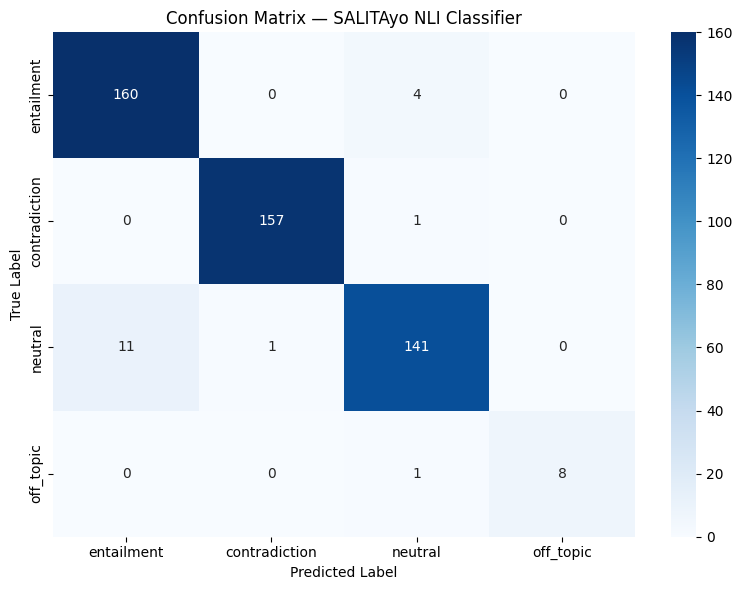

Confusion matrix saved.


In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_names,
    yticklabels=label_names
)
plt.title('Confusion Matrix — SALITAyo NLI Classifier')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.savefig(f'{PROJECT_DIR}/confusion_matrix.png', dpi=150)
plt.show()
print("Confusion matrix saved.")

In [ ]:
def predict_nli(premise, hypothesis, model, tokenizer, id2label, device='cpu'):
    """
    Predict NLI label for a single premise-hypothesis pair.
    Returns: (predicted_label, confidence_score, all_scores)
    """
    model.eval()
    model.to(device)

    inputs = tokenizer(
        premise,
        hypothesis,
        return_tensors='pt',
        truncation=True,
        max_length=256,
        padding=True
    ).to(device)

    with torch.no_grad():
        outputs = model(**inputs)
        logits = outputs.logits
        probabilities = torch.softmax(logits, dim=-1).squeeze()

    pred_id = probabilities.argmax().item()
    pred_label = id2label[pred_id]
    confidence = probabilities[pred_id].item()

    all_scores = {id2label[i]: probabilities[i].item() for i in range(len(id2label))}

    return pred_label, confidence, all_scores


# Test cases
test_cases = [
    ("AAIMS uses local processing and does not rely on cloud.", "AAIMS uses cloud servers."),
    ("The system detects mouth movement using MAR.", "The system tracks mouth activity using MAR."),
    ("The system monitors students during examinations.", "Basketball improves teamwork."),
    ("The system detects head pose and mouth movement.", "The system detects face absence."),
]

print("=" * 70)
print("CUSTOM INFERENCE TEST")
print("=" * 70)
for premise, hypothesis in test_cases:
    label, confidence, scores = predict_nli(premise, hypothesis, model, tokenizer, ID2LABEL)
    print(f"\nPremise:    {premise}")
    print(f"Hypothesis: {hypothesis}")
    print(f"Predicted:  {label.upper()} (confidence: {confidence:.3f})")
    print(f"All scores: { {k: f'{v:.3f}' for k, v in scores.items()} }")

CUSTOM INFERENCE TEST

Premise:    AAIMS uses local processing and does not rely on cloud.
Hypothesis: AAIMS uses cloud servers.
Predicted:  CONTRADICTION (confidence: 0.999)
All scores: {'entailment': '0.000', 'contradiction': '0.999', 'neutral': '0.000', 'off_topic': '0.000'}

Premise:    The system detects mouth movement using MAR.
Hypothesis: The system tracks mouth activity using MAR.
Predicted:  ENTAILMENT (confidence: 0.998)
All scores: {'entailment': '0.998', 'contradiction': '0.000', 'neutral': '0.001', 'off_topic': '0.000'}

Premise:    The system monitors students during examinations.
Hypothesis: Basketball improves teamwork.
Predicted:  CONTRADICTION (confidence: 0.995)
All scores: {'entailment': '0.000', 'contradiction': '0.995', 'neutral': '0.000', 'off_topic': '0.004'}

Premise:    The system detects head pose and mouth movement.
Hypothesis: The system detects face absence.
Predicted:  CONTRADICTION (confidence: 0.999)
All scores: {'entailment': '0.000', 'contradiction':

In [ ]:
from huggingface_hub import hf_hub_download
import shutil

FINAL_MODEL_DIR = f'{PROJECT_DIR}/final_model'

# Download the missing files directly from HuggingFace Hub
for filename in ['special_tokens_map.json', 'spm.model']:
    downloaded_path = hf_hub_download(
        repo_id="cross-encoder/nli-deberta-v3-small",
        filename=filename
    )
    dest = os.path.join(FINAL_MODEL_DIR, filename)
    shutil.copy(downloaded_path, dest)
    print(f"Copied: {filename}")

# Re-verify
print("\nFile check:")
for fname in expected:
    path = os.path.join(FINAL_MODEL_DIR, fname)
    status = "✅" if os.path.exists(path) else "❌ MISSING"
    print(f"  {status}  {fname}")

Copied: special_tokens_map.json
Copied: spm.model

File check:
  ✅  config.json
  ✅  tokenizer_config.json
  ✅  tokenizer.json
  ✅  special_tokens_map.json
  ✅  spm.model
  ✅  model.safetensors
  ✅  label_config.json


# **EXPORTING THE MODEL**

In [ ]:
# Option A: Zip and download directly
import shutil

zip_path = f'/content/salitayo_nli_model'
shutil.make_archive(zip_path, 'zip', FINAL_MODEL_DIR)

from google.colab import files
files.download(f'{zip_path}.zip')
print("Download initiated.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download initiated.
